# 🎓 Sri Lankan A/L Performance Prediction — Ensemble Learning

**ML & Pattern Recognition — Ensemble Learning Dashboard assignment**

Goal: predict a Sri Lankan student's **G.C.E. Advanced Level (2020)** result class —
**Not Qualified**, **Qualified** or **High Achiever** — from information that is available
independently of the subject grades, and compare **bagging**, **boosting**, **stacking / voting**
and a **hybrid (Random Forest + ANN)** against single-model baselines, with an interpretation of
*why* each model behaves the way it does.

- 🌐 Live dashboard: https://student-performance-app-tvqzyrlzyfe9ahvma6mtrj.streamlit.app
- 💻 GitHub: https://github.com/ManukaPathirana/student-performance-app

> ### 🤖 AI-use statement
> The code in this notebook, the data-preparation script, the `model.py` module and the Streamlit
> dashboard were **generated with the help of Claude (Anthropic), a generative-AI tool**. The
> student directed the work, reviewed the code, ran every cell and checked the results and
> interpretation.

## 1. Data — Sri Lankan G.C.E. A/L 2020 results
Source: public Kaggle upload of the **2020 G.C.E. Advanced Level examination results** (Department of
Examinations, Sri Lanka) — 337,553 candidates. `scripts/prepare_al_data.py` cleans it:

- keeps candidates who sat all 3 main subjects and the Common General Test (CGT), with a valid gender and birth date → **256,606 students**
- **Target** (from the 3 subject grades and the Z-score, which are *not* used as features):
  - **Not Qualified** – failed (F) at least one subject (36.4%)
  - **Qualified** – passed all 3 subjects, Z-score < 1.0 (47.9%)
  - **High Achiever** – passed all 3 subjects, Z-score ≥ 1.0 (15.7%)
- **Features (9):** stream (derived from the subject combination — the official stream column is blank for
  failed candidates, so using it would leak the answer), the 3 subjects, gender, age at the exam, syllabus
  (new/old), CGT score, General English grade
- a **stratified sample of 12,000 students** is used so that all 14 models (including SVM and stacking) can be
  trained live in the dashboard.

In [1]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, AdaBoostClassifier,
                              VotingClassifier, StackingClassifier)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
RS = 42
CLASSES = ["Not Qualified", "Qualified", "High Achiever"]

df = pd.read_csv("data/data.csv")
subjects = {int(k): v.title() for k, v in json.load(open("data/subjects.json")).items()}
streams = {0: "Arts", 1: "Commerce", 2: "Biological Science", 3: "Physical Science",
           4: "Engineering Technology", 5: "Biosystems Technology"}
print(df.shape)
readable = df.head().copy()
for c in ["Subject 1", "Subject 2", "Subject 3"]: readable[c] = readable[c].map(subjects)
readable["Stream"] = readable["Stream"].map(streams)
readable

(12000, 10)


,Stream,Subject 1,Subject 2,Subject 3,Gender,Age at exam,Syllabus,CGT score,General English,Target
0,Biological Science,Physics,Chemistry,Biology,0,19.1,1,58,1,Qualified
1,Arts,Logic & Scientific Method,Communication & Media Studies,Sinhala,0,18.8,1,38,0,Qualified
2,Arts,Political Science,History Of Sri Lanka & India,Buddhist Civilization,1,19.2,1,32,0,Not Qualified
3,Physical Science,Physics,Chemistry,Combined Mathematics,1,19.3,1,46,4,Not Qualified
4,Commerce,Economics,Business Studies,Accounting,1,19.6,1,50,2,Not Qualified


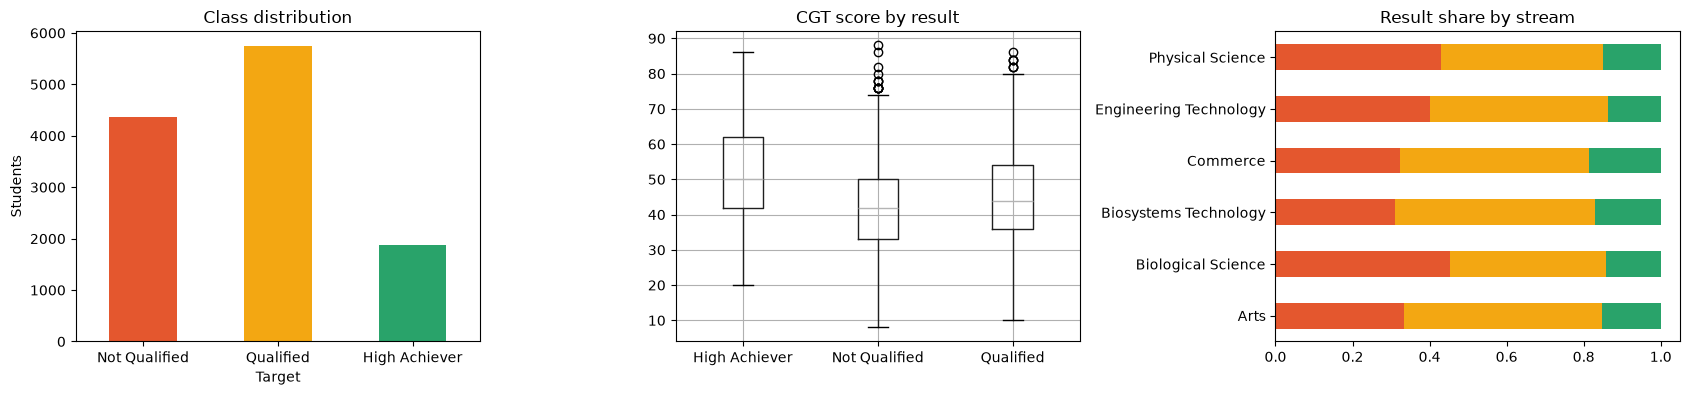

Target
Qualified        0.479
Not Qualified    0.364
High Achiever    0.157
Name: proportion, dtype: float64
Missing values: 0
               CGT score  Age at exam
Target                               
High Achiever      51.82        19.61
Not Qualified      41.72        19.72
Qualified          45.30        19.73


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
df["Target"].value_counts().reindex(CLASSES).plot.bar(ax=ax[0], color=["#E4572E", "#F3A712", "#29A36A"], rot=0)
ax[0].set_title("Class distribution"); ax[0].set_ylabel("Students")
df.boxplot(column="CGT score", by="Target", ax=ax[1]); ax[1].set_title("CGT score by result"); ax[1].set_xlabel("")
ct = pd.crosstab(df["Stream"].map(streams), df["Target"], normalize="index")[CLASSES]
ct.plot.barh(stacked=True, ax=ax[2], color=["#E4572E", "#F3A712", "#29A36A"], legend=False)
ax[2].set_title("Result share by stream"); ax[2].set_ylabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()
print(df["Target"].value_counts(normalize=True).round(3))
print("Missing values:", int(df.isna().sum().sum()))
print(df.groupby("Target")[["CGT score", "Age at exam"]].mean().round(2))

**Observations:** no missing values; the classes are imbalanced (High Achiever ≈ 16%). Higher CGT
scores clearly go with better results, and pass rates differ strongly between streams. *Qualified*
overlaps with both other classes — and we only use pre-result information — so we expect a **hard,
noisy problem** and report **macro-F1** next to accuracy.

In [3]:
X = df.drop(columns="Target").astype(float)
y = df["Target"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print("train:", X_tr.shape, " test:", X_te.shape)
print("Majority-class baseline accuracy:", round(y_te.value_counts(normalize=True).max(), 3))

results, fitted = [], {}
def evaluate(name, family, model):
    t0 = time.perf_counter(); model.fit(X_tr, y_tr); secs = time.perf_counter() - t0
    pred = model.predict(X_te)
    row = {"Model": name, "Family": family, "Accuracy": accuracy_score(y_te, pred),
           "F1 (macro)": f1_score(y_te, pred, average="macro"),
           "Recall High Achiever": (pred[y_te.values == "High Achiever"] == "High Achiever").mean(),
           "Train time (s)": secs}
    results.append(row); fitted[name] = model
    print(f"{name:34s} acc={row['Accuracy']:.3f}  F1={row['F1 (macro)']:.3f}  "
          f"recall(HA)={row['Recall High Achiever']:.2f}  ({secs:.1f}s)")
    return model
scaled = lambda est: make_pipeline(StandardScaler(), est)

train: (9600, 9)  test: (2400, 9)
Majority-class baseline accuracy: 0.479


## 2. Single-model baselines

In [4]:
evaluate("Logistic Regression", "Single model", scaled(LogisticRegression(max_iter=2000, C=0.5)))
evaluate("Decision Tree", "Single model", DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=RS))
evaluate("K-Nearest Neighbors", "Single model", scaled(KNeighborsClassifier(n_neighbors=15, weights="distance")))
evaluate("Support Vector Machine", "Single model", scaled(CalibratedClassifierCV(SVC(C=1.0), ensemble=False, cv=3)))
evaluate("Naive Bayes", "Single model", GaussianNB())
evaluate("Neural Network (MLP)", "Single model", scaled(MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3,
                                                     max_iter=500, early_stopping=True, random_state=RS)));

Logistic Regression                acc=0.554  F1=0.452  recall(HA)=0.12  (0.1s)


Decision Tree                      acc=0.565  F1=0.500  recall(HA)=0.23  (0.1s)


K-Nearest Neighbors                acc=0.535  F1=0.471  recall(HA)=0.21  (0.1s)


Support Vector Machine             acc=0.578  F1=0.464  recall(HA)=0.10  (39.5s)
Naive Bayes                        acc=0.516  F1=0.478  recall(HA)=0.38  (0.0s)


Neural Network (MLP)               acc=0.584  F1=0.502  recall(HA)=0.18  (2.2s)


## 3. Bagging — Bootstrap Aggregating
Many trees are trained **in parallel** on bootstrap samples and their votes are averaged, which
**reduces variance**.
- `BaggingClassifier` of decision trees (classic bagging)
- **Random Forest** = bagging + a random subset of features at every split (de-correlates the trees)
- **Extra Trees** = random forest with random split thresholds

First an **ablation**: fully grown trees (the scikit-learn default) vs regularised trees
(a minimum number of students per leaf).

In [5]:
for leaf in [1, 5, 20, 40]:
    m = RandomForestClassifier(n_estimators=200, min_samples_leaf=leaf, n_jobs=-1, random_state=RS).fit(X_tr, y_tr)
    p = m.predict(X_te)
    print(f"Random Forest min_samples_leaf={leaf:<3d} acc={accuracy_score(y_te, p):.3f}  F1={f1_score(y_te, p, average='macro'):.3f}")

Random Forest min_samples_leaf=1   acc=0.526  F1=0.468


Random Forest min_samples_leaf=5   acc=0.592  F1=0.509


Random Forest min_samples_leaf=20  acc=0.597  F1=0.511


Random Forest min_samples_leaf=40  acc=0.591  F1=0.486


Fully grown trees memorise noise in these pre-exam features (≈52–53% accuracy); with at least 20
students per leaf the forest generalises much better. The regularised versions are used from here on.

In [6]:
evaluate("Bagging (Decision Trees)", "Bagging", BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=10, random_state=RS),
                                                                  n_estimators=100, n_jobs=-1, random_state=RS))
evaluate("Random Forest", "Bagging", RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=RS))
evaluate("Extra Trees", "Bagging", ExtraTreesClassifier(n_estimators=200, min_samples_leaf=10, n_jobs=-1, random_state=RS));

Bagging (Decision Trees)           acc=0.589  F1=0.518  recall(HA)=0.22  (12.1s)


Random Forest                      acc=0.597  F1=0.511  recall(HA)=0.18  (1.3s)


Extra Trees                        acc=0.583  F1=0.464  recall(HA)=0.09  (0.8s)


## 4. Boosting
Weak learners are trained **sequentially**; each new tree concentrates on the students the previous
trees got wrong, which **reduces bias**.
- **Gradient Boosting** (histogram-based GBM, the same idea as LightGBM/XGBoost) fits each tree to the gradient of the loss
- **AdaBoost** re-weights mis-classified students

In [7]:
evaluate("Gradient Boosting", "Boosting", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=RS))
evaluate("AdaBoost", "Boosting", AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=RS));

Gradient Boosting                  acc=0.573  F1=0.513  recall(HA)=0.26  (16.7s)


AdaBoost                           acc=0.563  F1=0.407  recall(HA)=0.01  (7.1s)


## 5. Voting and Stacking
- **Soft voting**: average the predicted probabilities of different model types (RF + GBM + LR).
- **Stacking**: base models (RF, Extra Trees, GBM, KNN) produce out-of-fold probabilities (5-fold
  CV) and a **meta-learner** (Logistic Regression) learns how to combine them.
- As in the course template, the meta-learner's `C` is tuned with **GridSearchCV**, scoring on
  **macro recall** so the minority *High Achiever* class matters.

In [8]:
evaluate("Voting (soft)", "Stacking / Voting", VotingClassifier(
    estimators=[("rf", RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=RS)),
                ("gb", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=RS)),
                ("lr", scaled(LogisticRegression(max_iter=2000, C=0.5)))], voting="soft"))

stack = StackingClassifier(
    estimators=[("rf", RandomForestClassifier(n_estimators=150, min_samples_leaf=20, n_jobs=-1, random_state=RS)),
                ("et", ExtraTreesClassifier(n_estimators=150, min_samples_leaf=10, n_jobs=-1, random_state=RS)),
                ("gb", HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, random_state=RS)),
                ("knn", scaled(KNeighborsClassifier(n_neighbors=15)))],
    final_estimator=LogisticRegression(max_iter=2000), cv=5, stack_method="predict_proba")
evaluate("Stacking", "Stacking / Voting", stack);

Voting (soft)                      acc=0.588  F1=0.496  recall(HA)=0.16  (14.5s)


Stacking                           acc=0.592  F1=0.518  recall(HA)=0.21  (33.1s)


In [9]:
# GridSearchCV on the stacking meta-learner (scoring = macro recall), small grid to keep it fast
grid = GridSearchCV(stack, {"final_estimator__C": [0.1, 1.0, 10.0]}, scoring="recall_macro", cv=3, n_jobs=-1)
grid.fit(X_tr, y_tr)
print("best C:", grid.best_params_, " CV macro-recall:", round(grid.best_score_, 3))
evaluate("Stacking (GridSearchCV)", "Stacking / Voting", grid.best_estimator_);

best C: {'final_estimator__C': 10.0}  CV macro-recall: 0.492


Stacking (GridSearchCV)            acc=0.592  F1=0.519  recall(HA)=0.21  (14.7s)


## 6. Hybridization — Random Forest + ANN
The Random Forest's **out-of-fold class probabilities** (so there is no leakage) are added as 3
extra inputs to a neural network trained on the scaled original features. The forest supplies a
robust non-linear summary of the subject combinations; the ANN learns a smooth combination of it with
the raw signals. The class lives in `model.py` (also used by the dashboard):

In [10]:
import inspect
from model import HybridRFANN
print(inspect.getsource(HybridRFANN))

class HybridRFANN(ClassifierMixin, BaseEstimator):
    """Hybrid model: Random Forest + Artificial Neural Network.

    1. A Random Forest is trained; its *out-of-fold* class probabilities on the training
       set (5-fold cross_val_predict) become 3 extra features. Out-of-fold avoids leakage:
       the ANN never sees probabilities the forest produced for rows it trained on.
    2. An MLP (ANN) is trained on the scaled original features + the RF probabilities.
    The forest contributes robust non-linear splits on the raw attributes; the ANN learns
    a smooth combination of those forest "opinions" with the original signals.
    """

    def __init__(self, n_estimators=200, hidden_layer_sizes=(32,), alpha=1.0,
                 random_state=42):
        self.n_estimators = n_estimators
        self.hidden_layer_sizes = hidden_layer_sizes
        self.alpha = alpha  # strong L2: without it the ANN over-trusts the RF features
        self.random_state = random_state

    def _rf(self):

In [11]:
evaluate("Hybrid RF + ANN", "Hybrid", HybridRFANN(random_state=RS))
# ablation: the same hybrid with weak regularisation
evaluate("Hybrid RF + ANN (alpha=0.001)", "Hybrid", HybridRFANN(hidden_layer_sizes=(64, 32), alpha=1e-3, random_state=RS));

Hybrid RF + ANN                    acc=0.590  F1=0.506  recall(HA)=0.18  (7.1s)


Hybrid RF + ANN (alpha=0.001)      acc=0.554  F1=0.476  recall(HA)=0.18  (15.9s)


## 7. Comparison of all models

In [12]:
board = pd.DataFrame(results).sort_values(["Accuracy", "F1 (macro)"], ascending=False).reset_index(drop=True)
board.index += 1
board.style.format({"Accuracy": "{:.2%}", "F1 (macro)": "{:.3f}", "Recall High Achiever": "{:.2f}", "Train time (s)": "{:.1f}"})

,Model,Family,Accuracy,F1 (macro),Recall High Achiever,Train time (s)
1,Random Forest,Bagging,59.67%,0.511,0.18,1.3
2,Stacking,Stacking / Voting,59.21%,0.518,0.21,33.1
3,Stacking (GridSearchCV),Stacking / Voting,59.17%,0.519,0.21,14.7
4,Hybrid RF + ANN,Hybrid,58.96%,0.506,0.18,7.1
5,Bagging (Decision Trees),Bagging,58.92%,0.518,0.22,12.1
6,Voting (soft),Stacking / Voting,58.75%,0.496,0.16,14.5
7,Neural Network (MLP),Single model,58.38%,0.502,0.18,2.2
8,Extra Trees,Bagging,58.25%,0.464,0.09,0.8
9,Support Vector Machine,Single model,57.75%,0.464,0.10,39.5
10,Gradient Boosting,Boosting,57.33%,0.513,0.26,16.7


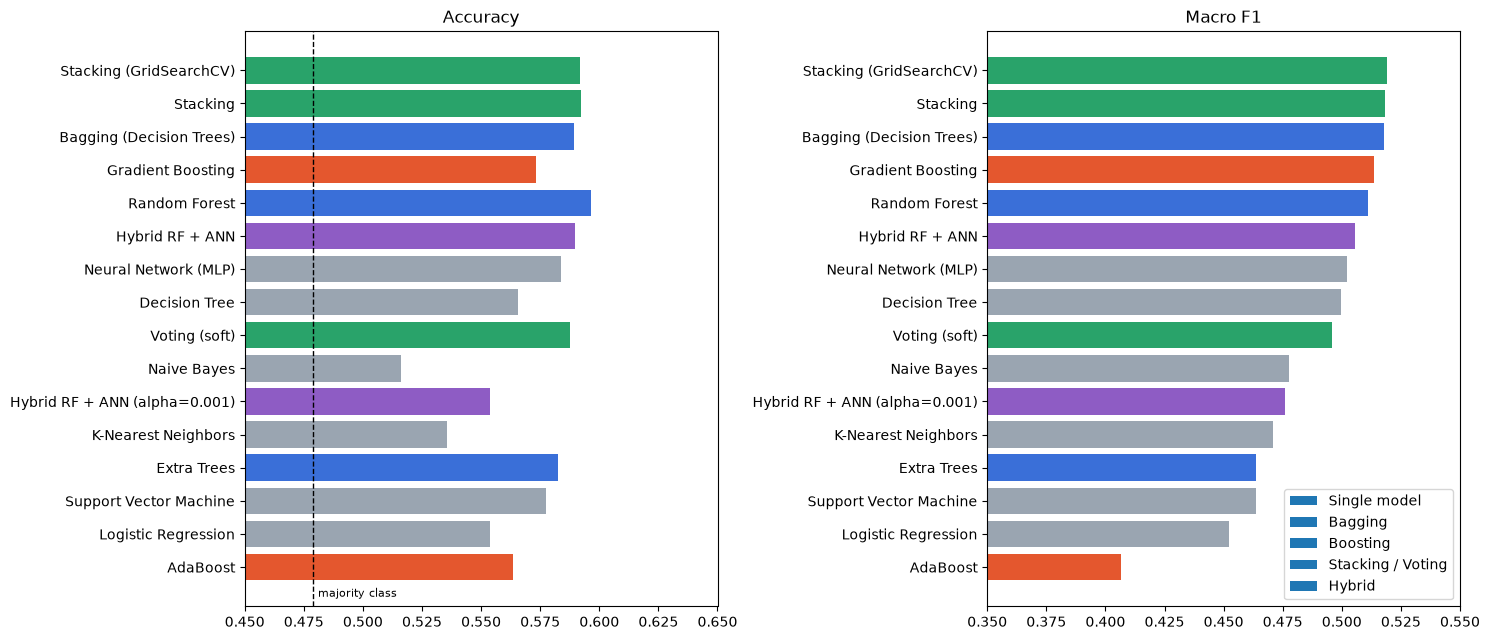

,Accuracy,F1 (macro),Recall High Achiever
Family,,,
Stacking / Voting,0.592083,0.518967,0.214854
Bagging,0.596667,0.517704,0.220159
Boosting,0.573333,0.513450,0.257294
Hybrid,0.589583,0.505759,0.175066
Single model,0.583750,0.502268,0.376658


In [13]:
colors = {"Single model": "#9AA5B1", "Bagging": "#3A6FD8", "Boosting": "#E4572E",
          "Stacking / Voting": "#29A36A", "Hybrid": "#8E5CC4"}
b = board.sort_values("F1 (macro)")
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
ax[0].barh(b["Model"], b["Accuracy"], color=b["Family"].map(colors)); ax[0].set_xlim(0.45, 0.65); ax[0].set_title("Accuracy")
ax[0].axvline(y_te.value_counts(normalize=True).max(), ls="--", c="k", lw=1); ax[0].text(0.481, -0.9, "majority class", fontsize=8)
ax[1].barh(b["Model"], b["F1 (macro)"], color=b["Family"].map(colors)); ax[1].set_xlim(0.35, 0.55); ax[1].set_title("Macro F1")
for f, c in colors.items(): ax[1].barh([], [], color=c, label=f)
ax[1].legend(loc="lower right"); plt.tight_layout(); plt.show()

board.groupby("Family")[["Accuracy", "F1 (macro)", "Recall High Achiever"]].max().sort_values("F1 (macro)", ascending=False)

### 7.1 Robustness check — 5-fold cross-validation
A single 80/20 split can be lucky, and many models are within 1–2 points of each other. 5-fold
stratified CV on all 12,000 students for the main representative of each family:

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
cv_models = {"Logistic Regression": scaled(LogisticRegression(max_iter=2000, C=0.5)),
             "Random Forest (bagging)": RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=RS),
             "Gradient Boosting (boosting)": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=RS),
             "Voting (soft)": fitted["Voting (soft)"],
             "Hybrid RF + ANN": HybridRFANN(random_state=RS)}
rows = []
for name, m in cv_models.items():
    acc = cross_val_score(m, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    f1 = cross_val_score(m, X, y, cv=cv, scoring="f1_macro", n_jobs=-1)
    rows.append({"Model": name, "CV accuracy": acc.mean(), "acc std": acc.std(),
                 "CV macro-F1": f1.mean(), "F1 std": f1.std()})
pd.DataFrame(rows).round(3)

,Model,CV accuracy,acc std,CV macro-F1,F1 std
0,Logistic Regression,0.548,0.007,0.444,0.006
1,Random Forest (bagging),0.582,0.007,0.487,0.008
2,Gradient Boosting (boosting),0.560,0.006,0.492,0.009
3,Voting (soft),0.578,0.010,0.489,0.012
4,Hybrid RF + ANN,0.582,0.010,0.493,0.011


## 8. Bagging vs Boosting in detail — Random Forest vs Gradient Boosting (and Stacking)

==================== Random Forest
               precision    recall  f1-score   support

Not Qualified      0.644     0.557     0.598       874
    Qualified      0.569     0.763     0.652      1149
High Achiever      0.660     0.180     0.283       377

     accuracy                          0.597      2400
    macro avg      0.624     0.500     0.511      2400
 weighted avg      0.611     0.597     0.574      2400

==================== Gradient Boosting


               precision    recall  f1-score   support

Not Qualified      0.603     0.562     0.582       874
    Qualified      0.568     0.686     0.621      1149
High Achiever      0.490     0.257     0.337       377

     accuracy                          0.573      2400
    macro avg      0.554     0.502     0.513      2400
 weighted avg      0.568     0.573     0.562      2400

==================== Stacking


               precision    recall  f1-score   support

Not Qualified      0.634     0.570     0.600       874
    Qualified      0.568     0.734     0.641      1149
High Achiever      0.606     0.212     0.314       377

     accuracy                          0.592      2400
    macro avg      0.603     0.505     0.518      2400
 weighted avg      0.598     0.592     0.575      2400



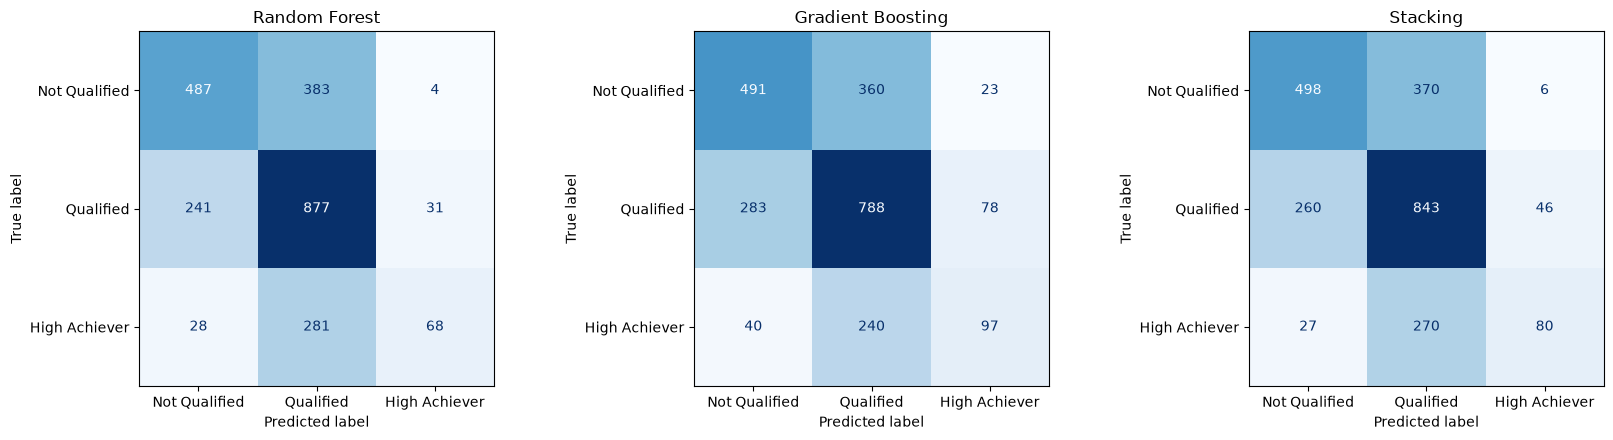

In [15]:
for name in ["Random Forest", "Gradient Boosting", "Stacking"]:
    print("=" * 20, name); print(classification_report(y_te, fitted[name].predict(X_te), labels=CLASSES, digits=3))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, name in zip(ax, ["Random Forest", "Gradient Boosting", "Stacking"]):
    ConfusionMatrixDisplay.from_estimator(fitted[name], X_te, y_te, labels=CLASSES, ax=a, cmap="Blues", colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.show()

## 9. Why do the models behave this way? — feature importance and model disagreement

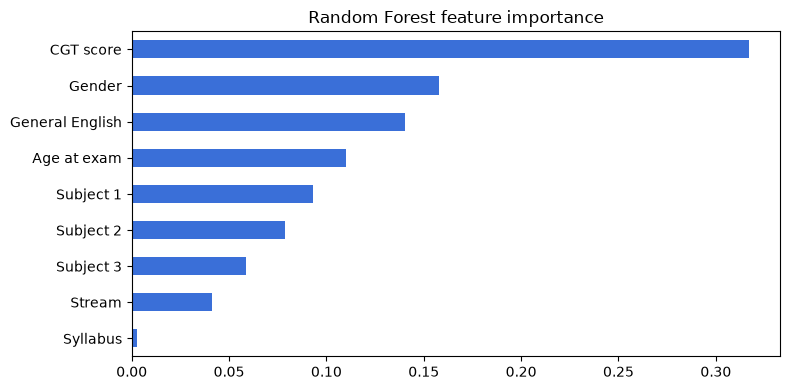

Target  Not Qualified  Qualified  High Achiever
Gender                                         
Female          0.283      0.532          0.186
Male            0.481      0.402          0.116
Target                     Not Qualified  Qualified  High Achiever
Age at exam                                                       
≤19.5 (first attempt age)          0.378      0.462          0.160
19.5–20.5                          0.337      0.505          0.158
>20.5 (likely repeat)              0.354      0.505          0.141


Share of test students on which two models disagree:


,Random Forest,Gradient Boosting,K-Nearest Neighbors,Logistic Regression
Random Forest,0.000,0.173,0.240,0.221
Gradient Boosting,0.173,0.000,0.247,0.295
K-Nearest Neighbors,0.240,0.247,0.000,0.333
Logistic Regression,0.221,0.295,0.333,0.000


In [16]:
imp = pd.Series(fitted["Random Forest"].feature_importances_, index=X.columns).sort_values()
imp.plot.barh(figsize=(8, 4), color="#3A6FD8", title="Random Forest feature importance")
plt.tight_layout(); plt.show()

print(pd.crosstab(df["Gender"].map({1: "Male", 0: "Female"}), df["Target"], normalize="index")[CLASSES].round(3))
age_band = pd.cut(df["Age at exam"], [0, 19.5, 20.5, 40], labels=["≤19.5 (first attempt age)", "19.5–20.5", ">20.5 (likely repeat)"])
print(pd.crosstab(age_band, df["Target"], normalize="index")[CLASSES].round(3))

names = ["Random Forest", "Gradient Boosting", "K-Nearest Neighbors", "Logistic Regression"]
preds = {n: fitted[n].predict(X_te) for n in names}
dis = pd.DataFrame([[np.mean(preds[a] != preds[b]) for b in names] for a in names], index=names, columns=names)
print("Share of test students on which two models disagree:")
dis.round(3)

## 10. Interpretation
*(numbers refer to the outputs above)*

**The problem is hard — and that is the point.** The models only see 9 attributes known
independently of the subject grades. Marks, school, district, private tuition and effort are not in the
data, so every model stays around 55–60% accuracy (vs ≈48% for always guessing *Qualified*). In such a
noisy setting, how a model handles **variance** and **bias** decides the ranking.

**Bagging vs boosting.** With fully grown trees, Random Forest overfits (≈52–53%); once each leaf must
contain at least 20 students it becomes one of the most accurate models. Averaging many de-correlated
trees **reduces variance**, which is exactly what noisy data needs. But averaging also pulls predictions
towards the large *Qualified* class, so RF finds few *High Achievers*. **Gradient Boosting** fits each new
tree to the remaining errors (**reduces bias**) and therefore recovers clearly more *High Achievers*,
at the price of more mistakes on the majority class — slightly lower accuracy, similar macro-F1. The
5-fold CV confirms this pattern: RF 58.2% accuracy / 0.487 macro-F1 vs GBM 56.0% / 0.492.

**Stacking and voting.** The base models disagree on 17–33% of students (disagreement matrix), so their
errors are far from identical. The stacking meta-learner learns which model to trust for which kind of
student, giving one of the best macro-F1 scores with balanced recall; soft voting is close behind.
GridSearchCV on the meta-learner's `C` (macro-recall scoring) picked C = 10, which barely changes the
result (macro-F1 0.518 → 0.519): the meta-learner only has 12 probability inputs to weight, so it is not
sensitive to regularisation.

**Hybrid RF + ANN.** Adding the forest's out-of-fold probabilities as inputs makes the ANN better than
the ANN alone and puts it among the top models. It cannot go far beyond the forest because both see the
same 9 attributes. In 5-fold CV it ties Random Forest on accuracy (58.2%) and has the best macro-F1
(0.493) of the models checked. The ablation shows that with weak regularisation (alpha = 0.001) the ANN
over-trusts the RF probabilities and drops to 55.4%.

**Single models.** Naive Bayes assumes independent features (stream and subjects are strongly linked);
KNN measures distances between *coded* subjects, which is not meaningful; Logistic Regression can only
draw linear boundaries over subject codes. These are the weakest models — ensembles fix exactly these
weaknesses. (Naive Bayes has the highest *High Achiever* recall, 0.38, only because it over-predicts that
class; its accuracy is the lowest at 51.6%.)

**What drives the result.** The CGT score is the strongest feature: it is a general-ability test taken
in the same exam. Gender and General English follow — female candidates and candidates with a good
English grade qualify more often in this data (male candidates fail a subject 48% of the time vs 28% for
female candidates). Age has a non-linear effect: 20–21-year-olds (typically a second attempt) fail less
often than first-time 19-year-olds but rarely reach Z ≥ 1.0, and candidates over 23 do much worse, so
trees can use it while a linear model cannot. The subject combination captures how hard each stream is to
pass. (Impurity-based importance favours continuous features, so CGT and age are somewhat over-weighted.)

**Cost vs benefit.** Stacking and SVM are the slowest to train; a regularised Random Forest gives
top accuracy in about one second — the best practical choice. Stacking is preferable when balanced recall
across all three result classes matters more than raw accuracy.

## 11. Save the best model (pickle) for the back end

In [17]:
import joblib, os
best_name = board.iloc[0]["Model"]
os.makedirs("artifacts", exist_ok=True)
joblib.dump(fitted[best_name], "artifacts/best_model.pkl", compress=3)
print("Saved", best_name, "->", "artifacts/best_model.pkl",
      f"({os.path.getsize('artifacts/best_model.pkl') / 1e6:.1f} MB)")

Saved Random Forest -> artifacts/best_model.pkl (2.4 MB)


## 12. Conclusion
On Sri Lankan A/L 2020 data, ensemble methods beat the weak single models, and the choice between
them is a **variance–bias trade-off**: regularised **bagging** (Random Forest) gives the best accuracy,
**boosting** finds more of the rare *High Achiever* students, and **stacking** and the **hybrid RF + ANN**
combine models with different errors into balanced, top-ranked predictions. The same 14 models are
trained live in the Streamlit dashboard, where users can also upload their own data, retrain, and
predict single students or whole files.

*🤖 Generated with the help of Claude (Anthropic); reviewed and run by the student.*